In [1]:
import pandas as pd
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

file_path = (
    project_root
    / "data"
    / "processed"
    / "branches_clean.csv"
)

df = pd.read_csv(file_path)

print("Jumlah cabang:", len(df))
display(df.head())

Jumlah cabang: 3


,branch_id,branch_name,city,address,opening_time,closing_time,phone,facilities,google_maps_url,instagram_url,gofood_url,grabfood_url,is_active,source_id,verification_status,data_type
0,BR001,Kopilogi,Garut,"Jl. Cikuray No.42, Regol, Kec. Garut Kota, Kab...",08:00,22:00,62 813 6786 6999,"wifi, ac, indoor, outdoor, toilet, parkir",https://maps.app.goo.gl/R479crDeXQ2gdv466,https://www.instagram.com/kopilogi?dlrf=MWVpcD...,https://gofood.link/a/zwzBrsq,NaN,True,SRC001,pending_pic,actual
1,BR002,Waroeng Kopilogi,Garut,"Jl. Guntur No.14, Paminggir, Kec. Garut Kota, ...",07:00,22:00,62 813 1222 0434,"wifi, ruang vip, karaoke, toilet, smoking area...",https://maps.app.goo.gl/DU4ZTnNwDtow4rj48,https://www.instagram.com/waroengkopilogi_garu...,https://gofood.link/a/BbAS6m1,NaN,True,SRC002,pending_pic,actual
2,BR003,Kopilogi Tasik,Tasikmalaya,"Jl. Dr. Sukarjo, Tawangsari, Kec. Tawang, Kota...",08:00,23:00,62 812 2228 1554,"wifi, ac, smoking area, mushola, toilet, slow ...",https://maps.app.goo.gl/tB6dk6wVaDYa7vzf8,https://www.instagram.com/kopilogi.tasik?cplk=...,https://gofood.link/a/LU2VaiJ,NaN,True,SRC003,pending_pic,actual


In [2]:
print("=== PENENTUAN ATRIBUT INFORMASI ===")

core_columns = [
    "branch_name",
    "city",
    "address",
    "opening_time",
    "closing_time",
    "phone",
    "google_maps_url"
]

supporting_columns = [
    "facilities",
    "instagram_url",
    "gofood_url",
    "grabfood_url"
]

print("Jumlah atribut inti:", len(core_columns))
print("Jumlah atribut pendukung:", len(supporting_columns))

=== PENENTUAN ATRIBUT INFORMASI ===
Jumlah atribut inti: 7
Jumlah atribut pendukung: 4


In [3]:
print("=== ANALISIS KELENGKAPAN CABANG ===")

def completeness_percentage(data, columns):
    values = data[columns].copy()

    # String kosong atau hanya spasi dianggap missing
    for col in columns:
        if pd.api.types.is_object_dtype(values[col]) or pd.api.types.is_string_dtype(values[col]):
            values[col] = values[col].replace(r"^\s*$", pd.NA, regex=True)

    return (values.notna().mean(axis=1) * 100).round(2)

df["core_completeness"] = completeness_percentage(
    df, core_columns
)

df["supporting_completeness"] = completeness_percentage(
    df, supporting_columns
)

df["overall_completeness"] = completeness_percentage(
    df, core_columns + supporting_columns
)

completeness_report = df[
    [
        "branch_id",
        "branch_name",
        "core_completeness",
        "supporting_completeness",
        "overall_completeness"
    ]
].copy()

display(completeness_report)

=== ANALISIS KELENGKAPAN CABANG ===


,branch_id,branch_name,core_completeness,supporting_completeness,overall_completeness
0,BR001,Kopilogi,100.0,75.0,90.91
1,BR002,Waroeng Kopilogi,100.0,75.0,90.91
2,BR003,Kopilogi Tasik,100.0,75.0,90.91


In [4]:
print("=== ANALISIS STATUS VERIFIKASI ===")

verification_counts = (
    df["verification_status"]
    .value_counts(dropna=False)
)

display(verification_counts)

verified_count = (
    df["verification_status"] == "verified_pic"
).sum()

verification_rate = (
    verified_count / len(df) * 100
    if len(df) > 0 else 0
)

print("Jumlah cabang:", len(df))
print("Cabang terverifikasi PIC:", verified_count)
print(f"Verification Rate: {verification_rate:.2f}%")

=== ANALISIS STATUS VERIFIKASI ===


verification_status
pending_pic    3
Name: count, dtype: int64

Jumlah cabang: 3
Cabang terverifikasi PIC: 0
Verification Rate: 0.00%


In [6]:
print("=== INFORMASI YANG BELUM LENGKAP ===")

all_columns = core_columns + supporting_columns

missing_details = []

for _, row in df.iterrows():
    for col in all_columns:
        value = row[col]

        if pd.isna(value) or (
            isinstance(value, str) and value.strip() == ""
        ):
            missing_details.append({
                "branch_id": row["branch_id"],
                "branch_name": row["branch_name"],
                "missing_attribute": col
            })

missing_details_df = pd.DataFrame(
    missing_details,
    columns=[
        "branch_id",
        "branch_name",
        "missing_attribute"
    ]
)

display(missing_details_df)

=== INFORMASI YANG BELUM LENGKAP ===


,branch_id,branch_name,missing_attribute
0,BR001,Kopilogi,grabfood_url
1,BR002,Waroeng Kopilogi,grabfood_url
2,BR003,Kopilogi Tasik,grabfood_url


In [7]:
from pathlib import Path

reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# Simpan kelengkapan per cabang
completeness_report.to_csv(
    reports_dir / "branches_completeness.csv",
    index=False,
    encoding="utf-8-sig"
)

# Simpan atribut yang belum lengkap
missing_details_df.to_csv(
    reports_dir / "branches_missing_details.csv",
    index=False,
    encoding="utf-8-sig"
)

# Simpan ringkasan status verifikasi
verification_report = (
    df["verification_status"]
    .value_counts(dropna=False)
    .rename_axis("verification_status")
    .reset_index(name="jumlah_cabang")
)

verification_report.to_csv(
    reports_dir / "branches_verification.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Seluruh hasil analisis PB-01 berhasil disimpan.")

Seluruh hasil analisis PB-01 berhasil disimpan.


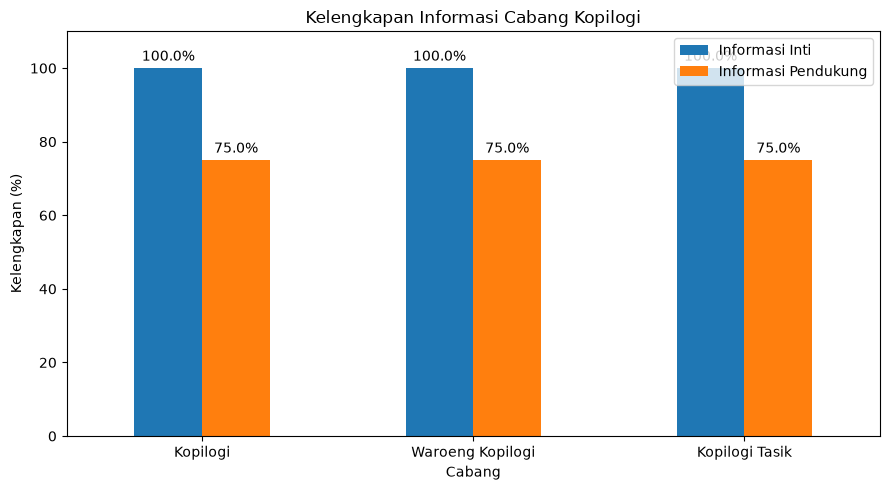

In [8]:
import matplotlib.pyplot as plt

plot_data = completeness_report.set_index("branch_name")[
    ["core_completeness", "supporting_completeness"]
]

ax = plot_data.plot(kind="bar", figsize=(9, 5))

plt.title("Kelengkapan Informasi Cabang Kopilogi")
plt.xlabel("Cabang")
plt.ylabel("Kelengkapan (%)")
plt.ylim(0, 110)
plt.xticks(rotation=0)
plt.legend(["Informasi Inti", "Informasi Pendukung"])

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()

plt.savefig(
    reports_dir / "branches_completeness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()